In [ ]:
# 1. Create the hidden Kaggle directory
!mkdir -p ~/.kaggle

# 2. Move your uploaded API key into that directory
!cp kaggle.json ~/.kaggle/

# 3. Secure the file permissions (required by Kaggle)
!chmod 600 ~/.kaggle/kaggle.json


cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('Crop_recommendation.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [ ]:
# Check dataset shape
print("Shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check target classes
print("\nCrop Classes:")
print(df['label'].value_counts())

Shape: (2200, 8)

Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Data Types:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

Missing Values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate Rows: 0

Crop Classes:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


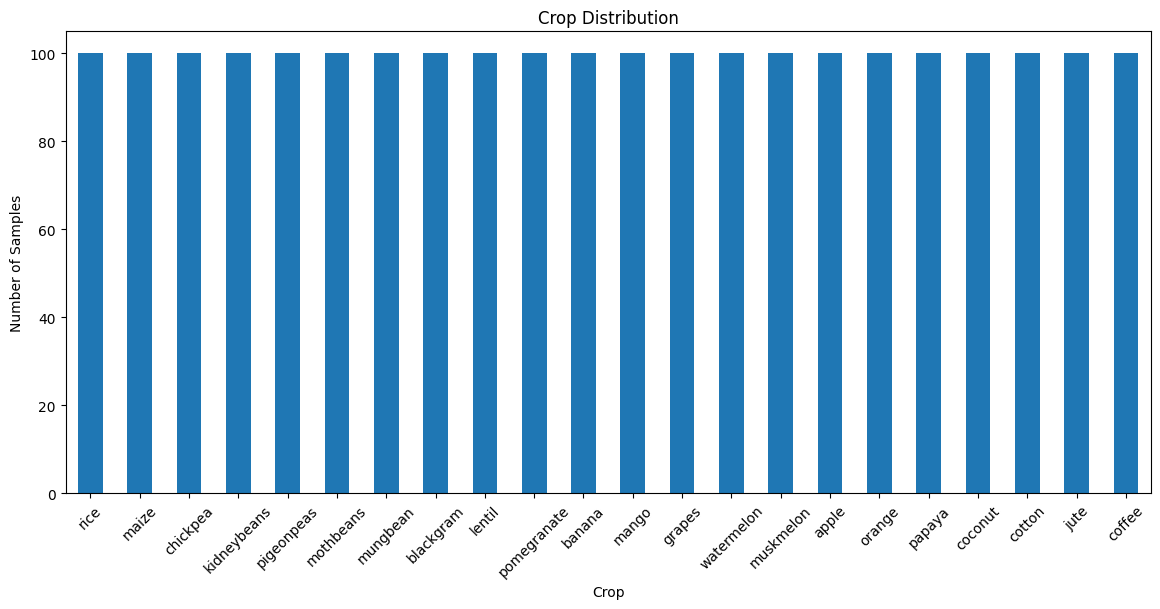

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

df['label'].value_counts().plot(kind='bar')

plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.title("Crop Distribution")
plt.xticks(rotation=45)
plt.show()

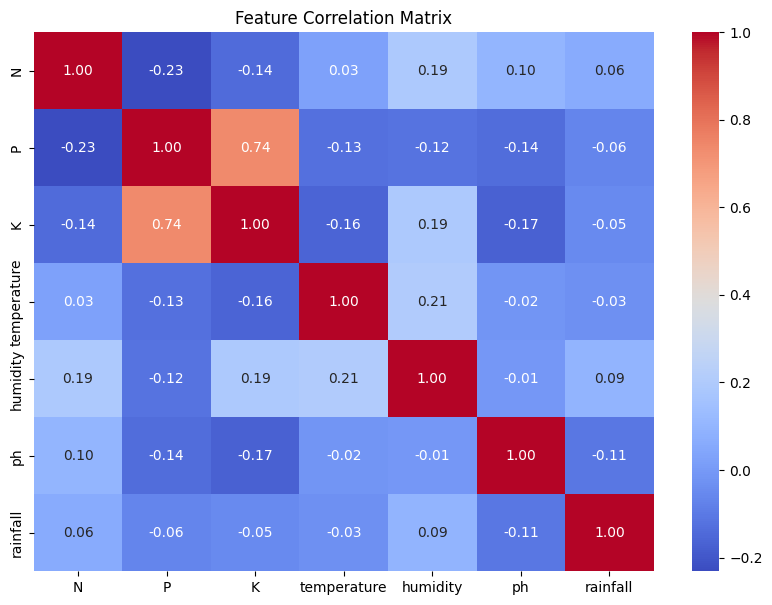

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

# Define the features for the correlation matrix (excluding the 'label' column)
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Matrix")
plt.show()

In [ ]:
# Input features
X = df[['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']]

# Target variable
y = df['label']

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget:")
print(y.head())

X shape: (2200, 7)
y shape: (2200,)

Input features:
    N   P   K  temperature   humidity        ph    rainfall
0  90  42  43    20.879744  82.002744  6.502985  202.935536
1  85  58  41    21.770462  80.319644  7.038096  226.655537
2  60  55  44    23.004459  82.320763  7.840207  263.964248
3  74  35  40    26.491096  80.158363  6.980401  242.864034
4  78  42  42    20.130175  81.604873  7.628473  262.717340

Target:
0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: object


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1760, 7)
Testing data: (440, 7)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
y_pred = rf_model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

print("\nActual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
['orange' 'banana' 'cotton' 'maize' 'orange' 'chickpea' 'rice' 'blackgram'
 'banana' 'orange']

Actual values:
['orange' 'banana' 'cotton' 'maize' 'orange' 'chickpea' 'rice' 'blackgram'
 'banana' 'orange']


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:", accuracy)
print("Random Forest Accuracy: {:.2f}%".format(accuracy * 100))

Random Forest Accuracy: 0.9954545454545455
Random Forest Accuracy: 99.55%


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

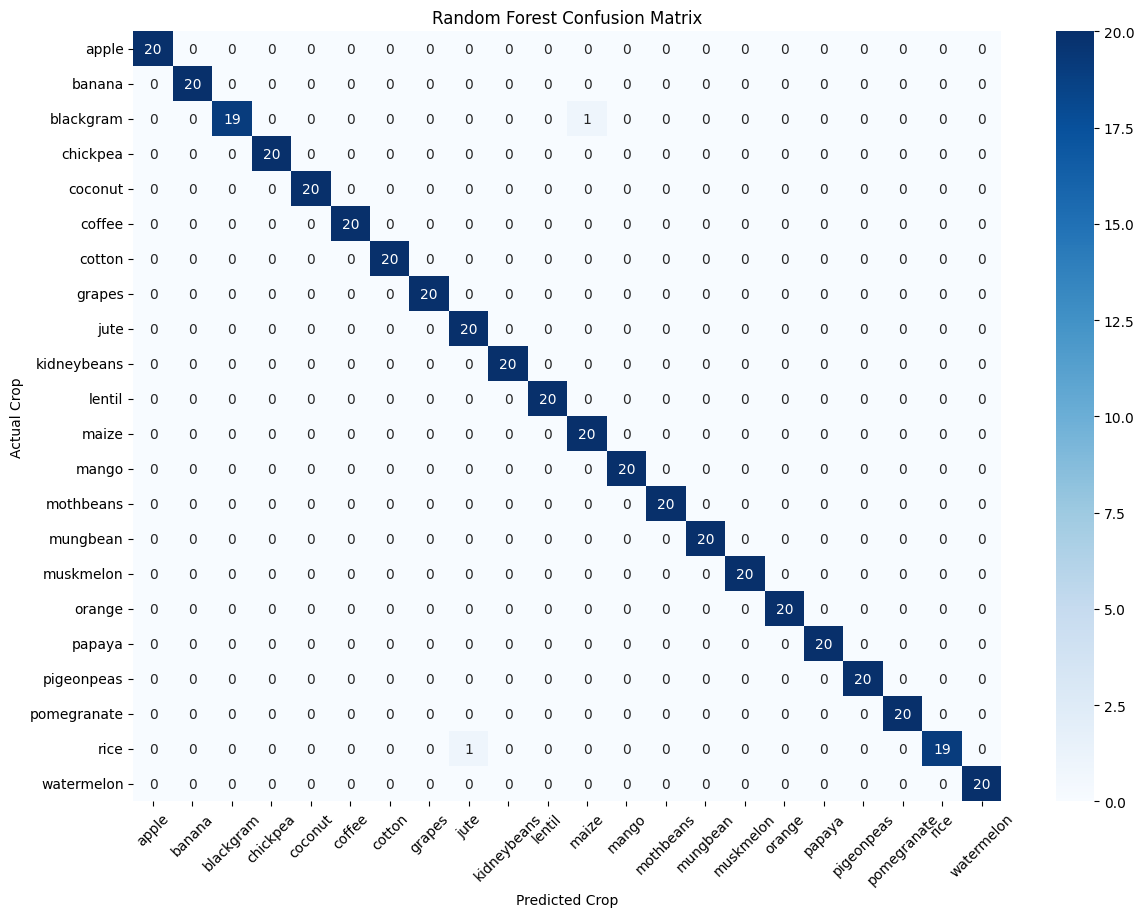

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.title("Random Forest Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from Random Forest
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

# Sort from highest to lowest
importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

       Feature  Importance
6     rainfall    0.219641
4     humidity    0.217058
2            K    0.180813
1            P    0.151342
0            N    0.103356
3  temperature    0.075485
5           ph    0.052305


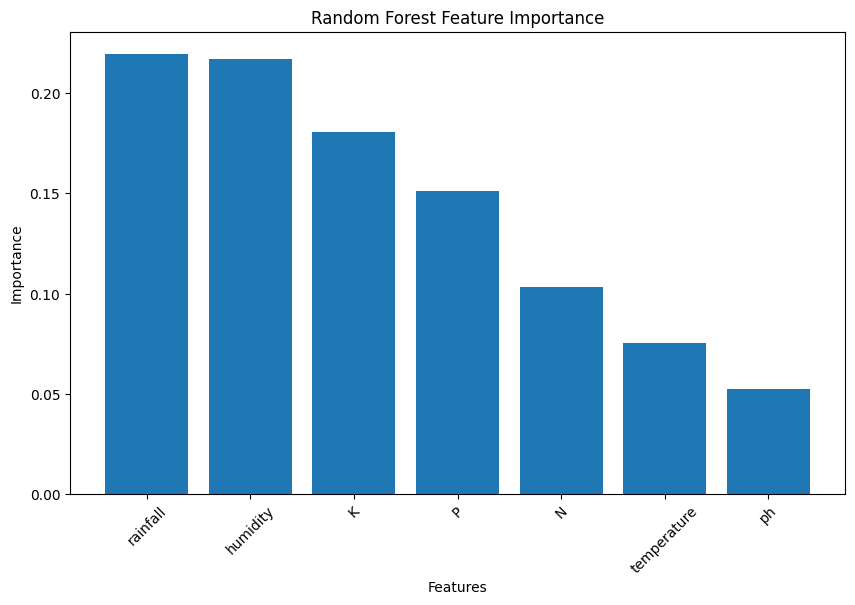

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    importance['Feature'],
    importance['Importance']
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.xticks(rotation=45)

plt.show()

In [ ]:
from xgboost import XGBClassifier

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Crop classes:")
print(label_encoder.classes_)

Crop classes:
['apple' 'banana' 'blackgram' 'chickpea' 'coconut' 'coffee' 'cotton'
 'grapes' 'jute' 'kidneybeans' 'lentil' 'maize' 'mango' 'mothbeans'
 'mungbean' 'muskmelon' 'orange' 'papaya' 'pigeonpeas' 'pomegranate'
 'rice' 'watermelon']


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='mlogloss'
)

xgb_model.fit(
    X_train,
    y_train_encoded
)

print("XGBoost training completed!")

XGBoost training completed!


In [ ]:
# Predict
y_pred_xgb = xgb_model.predict(X_test)

# Convert numbers back to crop names
y_pred_xgb_labels = label_encoder.inverse_transform(y_pred_xgb)

print("First 10 predictions:")
print(y_pred_xgb_labels[:10])

print("\nActual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
['orange' 'banana' 'cotton' 'maize' 'orange' 'chickpea' 'rice' 'blackgram'
 'banana' 'orange']

Actual values:
['orange' 'banana' 'cotton' 'maize' 'orange' 'chickpea' 'rice' 'blackgram'
 'banana' 'orange']


In [ ]:
from sklearn.metrics import accuracy_score

xgb_accuracy = accuracy_score(
    y_test_encoded,
    y_pred_xgb
)

print("XGBoost Accuracy:", xgb_accuracy)
print("XGBoost Accuracy: {:.2f}%".format(xgb_accuracy * 100))

XGBoost Accuracy: 0.9863636363636363
XGBoost Accuracy: 98.64%


In [ ]:
print("Model Comparison")
print("----------------------------")
print(f"Random Forest : {accuracy * 100:.2f}%")
print(f"XGBoost       : {xgb_accuracy * 100:.2f}%")

Model Comparison
----------------------------
Random Forest : 99.55%
XGBoost       : 98.64%


In [ ]:
##Create the prediction function

In [ ]:
def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):

    input_data = [[
        N,
        P,
        K,
        temperature,
        humidity,
        ph,
        rainfall
    ]]

    prediction = rf_model.predict(input_data)

    return prediction[0]

In [ ]:
result = recommend_crop(
    90,
    42,
    43,
    20.879,
    82.002,
    6.502,
    202.936
)

print("Recommended Crop:", result)

Recommended Crop: rice


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
N = float(input("Enter Nitrogen (N): "))
P = float(input("Enter Phosphorus (P): "))
K = float(input("Enter Potassium (K): "))
temperature = float(input("Enter Temperature (°C): "))
humidity = float(input("Enter Humidity (%): "))
ph = float(input("Enter Soil pH: "))
rainfall = float(input("Enter Rainfall (mm): "))

result = recommend_crop(
    N,
    P,
    K,
    temperature,
    humidity,
    ph,
    rainfall
)

print("\nRecommended Crop:", result)

Enter Nitrogen (N): 34
Enter Phosphorus (P): 23
Enter Potassium (K): 45
Enter Temperature (°C): 32
Enter Humidity (%): 23
Enter Soil pH: 23
Enter Rainfall (mm): 34

Recommended Crop: kidneybeans


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
import joblib

joblib.dump(rf_model, "crop_recommendation_model.pkl")

print("Crop recommendation model saved successfully!")

Crop recommendation model saved successfully!


In [ ]:
import pandas as pd

def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):

    input_data = pd.DataFrame([[
        N,
        P,
        K,
        temperature,
        humidity,
        ph,
        rainfall
    ]], columns=[
        'N',
        'P',
        'K',
        'temperature',
        'humidity',
        'ph',
        'rainfall'
    ])

    prediction = rf_model.predict(input_data)

    return prediction[0]

In [ ]:
result = recommend_crop(
    90,
    42,
    43,
    20.879,
    82.002,
    6.502,
    202.936
)

print("Recommended Crop:", result)

Recommended Crop: rice
